# Lab01 · КТвД · доп. задание: пропорции шрифтов

**Две случайные величины одной природы: высота строчных (x-height) и толщина основного штриха.**

| | |
|---|---|
| Датасет | собственный: шрифты Google Fonts, измерены по контурам букв скриптом `labfont` (fontTools) |
| Генеральная совокупность | собранная коллекция, $N = 100$ семейств; одно начертание на семейство, ближайшее к Regular |
| Категории | display 20, serif 20, mono 20, handwriting 20, sans 20 |
| Случайные величины | RV01 **x-height**, RV02 **толщина штриха «l»**; обе в долях кегля |
| Автор | Быкова Кристина Денисовна (ИСУ 501322), группа 27, трек КТвД |
| Код | `labfont/` (измерения, схема), `labstat/` (статистические функции из основной части, автор Нефедьева А. С.), тесты `tests/test_labfont.py` |

<a id="toc"></a>
**Содержание**

- [1. Dataset: коллекция шрифтов](#ds)
    - [1.1 Как измерено](#ds-how)
    - [1.2 Обзор данных](#ds-eda)
- [2. Random Variable 01 (x-height)](#rv1)
    - [2.1 Description (природа события)](#rv1-desc)
    - [2.2 EDA & Distribution](#rv1-eda)
- [3. Random Variable 02 (толщина штриха)](#rv2)
    - [3.1 Description (природа события)](#rv2-desc)
    - [3.2 EDA & Distribution](#rv2-eda)
- [4. Independence: x-height и толщина штриха](#dep)
    - [4.1 Гипотеза: у гротесков x-height больше, чем у антикв](#hyp)
- [5. Resume](#resume)
    - [5.1 Итоговые метрики](#res-metrics)
    - [5.2 Выводы](#res-concl)
    - [5.3 Литература](#res-lit)
    - [5.4 cat_mark_table](#res-marks)

*Код в ячейках скрыт; раскрыть — щелчок по полоске слева от ячейки.*

In [1]:
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
import sys; sys.path.insert(0, ".")   # пакеты labstat и labfont лежат в корне репозитория

from labstat import dependence, describe as dsc, distributions as dist, hypotheses as hyp, stochastic, plots
from labfont import fontplots as fp
from labfont.illustrate import measurement_figure

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 4)
plots.style()
SEED = 2026
raw = pd.read_csv("data/fonts.csv")
raw["category"] = raw["category"].fillna("")
# Шрифты без настоящих строчных (капитель SC, униказ): их «x» — это капитель или прописная
print("Исключены (нет строчных букв):", raw.family[raw.no_lowercase].tolist())
fonts = raw[~raw.no_lowercase].reset_index(drop=True)
OTHERS = ['cap_height', 'contrast', 'width_o', 'adv_mean', 'weight_class']
fonts.shape

Исключены (нет строчных букв): ['Alegreya SC', 'Cinzel Decorative', 'Cormorant SC', 'Rubik Mono One', 'Spectral SC', 'Yuji Hentaigana Akari']


(100, 20)

<a id="ds"></a>
## 1. Dataset: коллекция шрифтов

<a id="ds-how"></a>
### 1.1 Как измерено

Шрифты взяты из двух источников: 37 семейств выбраны автором на fonts.google.com, ещё 69 добавлены
**случайным отбором** из репозитория Google Fonts (github.com/google/fonts) так, чтобы в каждой категории было по 20
(`tools/sample_google_fonts.py`, `random.Random(2026)`). Категории — по каталогу Google Fonts (`data/font_categories.csv`).
Скрипт `python -m labfont.collect fonts/ data/fonts.csv` берёт из архива одно начертание, ближайшее к Regular
(прямое, вес 400; у вариативного шрифта создаётся экземпляр с $\mathrm{wght} = 400$), и меряет контуры букв.

Все длины делятся на размер кегля в единицах шрифта (UPM), поэтому величины **безразмерные, в долях кегля**:
x-height $= 0.5$ значит, что при кегле 16 px строчные буквы высотой 8 px.

- **x-height**: верхняя точка контура «x»;
- **толщина штриха**: ширина вертикали «l» на линии $y = \tfrac12\,$x-height. Контур дробится в многоугольник,
  по точкам пересечения с горизонталью находятся участки «чернил» (правило ненулевой обмотки, как у растеризатора шрифтов);
- **контраст**: толщина боков «o» к толщине верха и низа; **ширина**: ширина «o» к x-height.

**Очистка.** Измерено семейств: 106. Исключены (6) шрифты без настоящих строчных букв
(Alegreya SC, Cinzel Decorative, Cormorant SC, Rubik Mono One, Spectral SC, Yuji Hentaigana Akari): в капительных (SC) и декоративных шрифтах на месте «x» стоит капитель или прописная форма,
и «x-height» у них — это не высота строчных. Признак: у «l» нет выносного элемента (она не выше «x» больше чем в 1.15 раза;
у остальных шрифтов отношение от 1.25). Spectral SC вдобавок повторяет Spectral. Начертания оптических размеров
(Inter 18pt, Fraunces 72pt) и ширин (Roboto SemiCondensed) объединены с основным семейством по папке Google Fonts.

**Ограничение.** Выборка смешанная: часть шрифтов выбрана по вкусу, часть — случайно. Поэтому генеральная совокупность
здесь — «эта коллекция», а не все шрифты мира; выводы о Google Fonts в целом делаются осторожно.

Почему одно начертание на семейство: Bold, Italic и Regular одного семейства рисовал один дизайнер,
это зависимые наблюдения. Наблюдение здесь — семейство.


<sub>[↑ к содержанию](#toc)</sub>

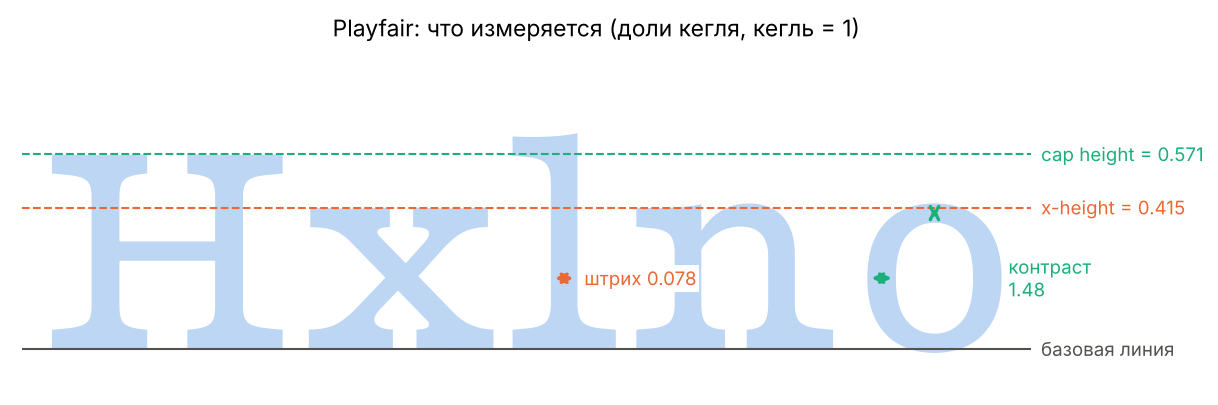

In [2]:
fig, m = measurement_figure(Path("data/fonts_sample/Playfair-VariableFont.ttf").read_bytes())
plots.save(fig, "fonts_measure.png");

<a id="fig1"></a>
*Рис. 1. Схема измерений на контурах настоящего шрифта: x-height, высота прописных, толщина штриха «l» и контраст «o».*

<a id="ds-eda"></a>
### 1.2 Обзор данных


<sub>[↑ к содержанию](#toc)</sub>

In [3]:
print("Семейств:", len(fonts), "| с кириллицей:", int(fonts.has_cyrillic.sum()), "| вариативных:", int(fonts.is_variable.sum()))
print("Вес OS/2 у выбранных начертаний:", fonts.weight_class.value_counts().sort_index().to_dict())
fonts.groupby("category")[["x_height", "stem", "contrast", "width_o"]].median().round(3)

Семейств: 100 | с кириллицей: 39 | вариативных: 32
Вес OS/2 у выбранных начертаний: {400: 100}


,x_height,stem,contrast,width_o
category,,,,
display,0.500,0.114,1.303,1.008
handwriting,0.471,0.065,1.028,0.889
mono,0.519,0.084,1.138,0.901
sans,0.521,0.087,1.202,0.941
serif,0.460,0.082,2.092,0.981


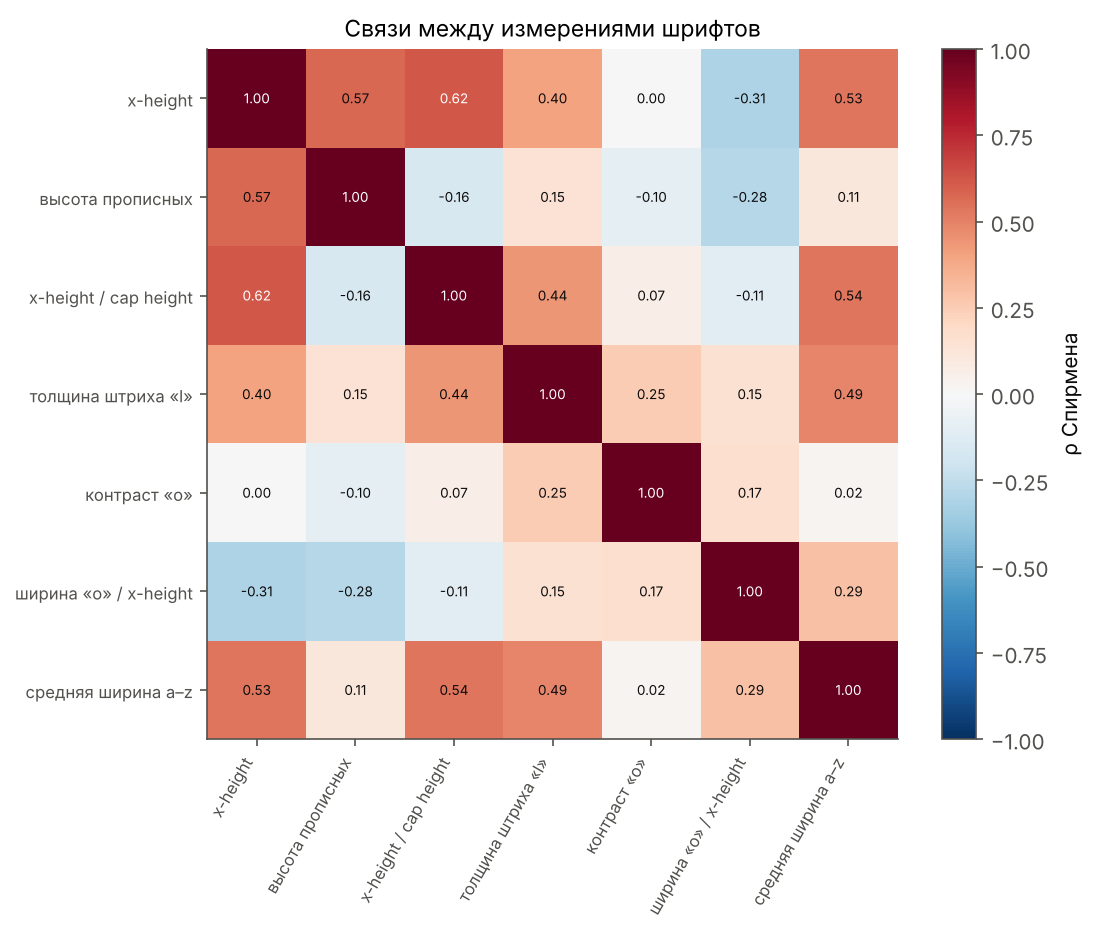

In [4]:
cols = ["x_height", "cap_height", "x_to_cap", "stem", "contrast", "width_o", "adv_mean"]
plots.corr_heatmap(fonts[cols].rename(columns=fp.COL_RU).corr(method="spearman"), "fonts_corr.png", title="Связи между измерениями шрифтов");

<a id="fig2"></a>
*Рис. 2. Ранговые корреляции Спирмена $\rho$ между измерениями шрифтов.*

<a id="rv1"></a>
## 2. Random Variable 01 (x-height)

<sub>[↑ к содержанию](#toc)</sub>

<a id="rv1-desc"></a>
### 2.1 Description (природа события)

**Величина.** Высота строчных в долях кегля; точность измерения $1/\mathrm{UPM}$ (у большинства шрифтов
$1/1000$ или $1/2048$ кегля), то есть $\le 0.001$.

**Событие.** Из коллекции случайно выбирается семейство шрифтов, у его Regular измеряется высота строчных.

**Что посчитано для проверки стохастической природы.** Прогноз величины по остальным измерениям
(высота прописных, контраст, ширина «o», средняя ширина букв, вес OS/2 и вторая величина) на 5-кратной кросс-валидации: линейная регрессия и $k = 5$ ближайших
соседей. Если бы величина вычислялась формулой из остальных, $R^2 \approx 1$, а остаток был бы порядка
точности $0.001$. Плюс разброс внутри одной категории: если бы категория (гротеск, антиква…) задавала величину,
внутри категории разброса бы не было.

**TODO КТвД: природа события своими словами.** _Вопросы: кто и почему выбирает x-height шрифта? можно ли его
вычислить по другим пропорциям или по категории? что из расчёта ниже говорит «за» и «против»?_


<sub>[↑ к содержанию](#toc)</sub>

Линейная модель: R² = 0.671, СКО остатка 0.0377 кегля
5 ближайших соседей: R² = 0.509, СКО остатка 0.0451 кегля
Наблюдений в модели: 98 (без шрифтов с неизмеренным контрастом)
СКО самой величины 0.0660; точность измерения ≤ 0.001


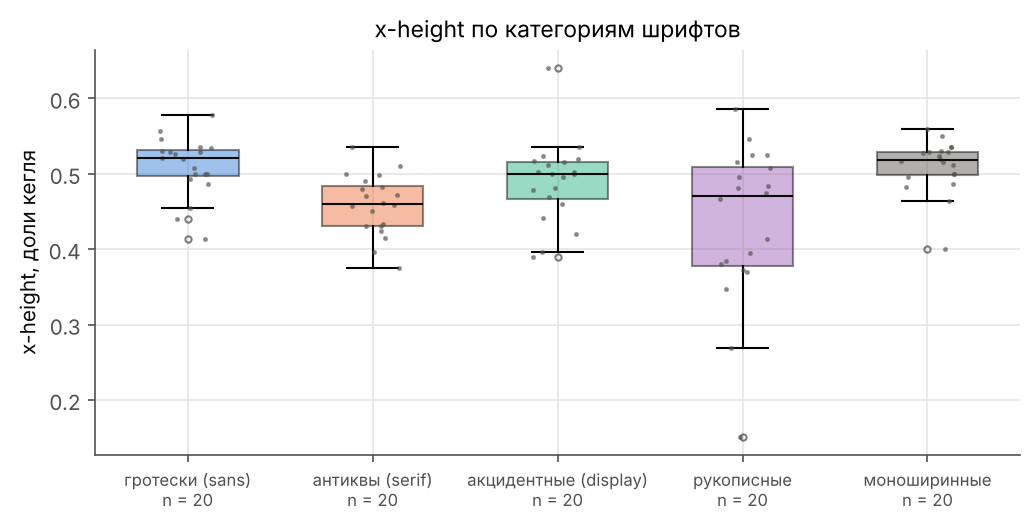

In [5]:
full = fonts.dropna(subset=OTHERS + ["x_height", "stem"])   # без шрифтов с неизмеренным контрастом
y = full["x_height"].to_numpy()
Xo = full[[c for c in OTHERS + ["x_height", "stem"] if c != "x_height"]].to_numpy()
lin = stochastic.cv_r2_linear(Xo, y, k=5, seed=SEED)
knn = stochastic.cv_r2_knn(Xo, y, k_neighbors=5, k=5, seed=SEED)
print(f"Линейная модель: R² = {lin['r2_cv']:.3f}, СКО остатка {lin['resid_std']:.4f} кегля")
print(f"5 ближайших соседей: R² = {knn['r2_cv']:.3f}, СКО остатка {knn['resid_std']:.4f} кегля")
print(f"Наблюдений в модели: {len(full)} (без шрифтов с неизмеренным контрастом)")
print(f"СКО самой величины {y.std(ddof=1):.4f}; точность измерения ≤ 0.001")
fp.box_by_category(fonts, "x_height", "x-height", "доли кегля", "fonts_x_height_by_cat.png");

<a id="fig_x_height_cat"></a>
*Рис. 3. x-height по категориям шрифтов: ящики с усами и сами наблюдения.*

**Результаты:**

- Линейная модель по остальным измерениям: $R^2 = 0.671$, СКО остатка 0.0377 кегля.
- 5 ближайших соседей: $R^2 = 0.509$, СКО остатка 0.0451 кегля.
- СКО самой величины 0.0660 (шрифтов в модели: 98), точность измерения $\le 0.001$: даже лучший остаток (0.0377) больше точности, отношение $\approx 38$.
- Средний по категориям разброс внутри категории составляет 82 % общего СКО.

<a id="rv1-eda"></a>
### 2.2 EDA & Distribution

<sub>[↑ к содержанию](#toc)</sub>

In [6]:
x_x_height = fonts["x_height"].to_numpy()
print("Выбросов по правилу 1.5·IQR:", dsc.iqr_outliers(x_x_height).sum())
display(dsc.compare_table({"все": x_x_height} | {c: g["x_height"] for c, g in fonts.groupby("category")}).T)
fit_x_height = dist.fit_candidates(x_x_height)
fit_x_height

Выбросов по правилу 1.5·IQR: 4


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
все,100.0,0.4807,0.0044,0.0663,0.1379,0.1512,0.4566,0.4985,0.5236,0.6401,0.0670,0.5000,-1.6591,5.5849,80.0,3.0428e-05
display,20.0,0.4899,0.0030,0.0548,0.1118,0.3890,0.4668,0.5000,0.5155,0.6401,0.0487,0.5000,0.4117,1.4950,19.0,6.0034e-04
handwriting,20.0,0.4345,0.0108,0.1040,0.2395,0.1512,0.3780,0.4709,0.5096,0.5859,0.1316,0.1512,-1.0056,0.8845,20.0,3.0428e-05
mono,20.0,0.5106,0.0012,0.0349,0.0683,0.4000,0.4990,0.5188,0.5287,0.5600,0.0297,0.5000,-1.6023,3.1958,17.0,1.3203e-03
sans,20.0,0.5100,0.0015,0.0393,0.0771,0.4140,0.4976,0.5206,0.5310,0.5780,0.0334,0.5000,-0.7973,0.4393,18.0,9.7656e-04
serif,20.0,0.4586,0.0016,0.0400,0.0872,0.3750,0.4309,0.4600,0.4840,0.5360,0.0531,0.3750,-0.1807,-0.4006,20.0,3.3594e-04


,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
weibull_min,3,140.3320,-274.6639,-266.8484,0.1047,"(24.3521, -0.7798, 1.2879)"
skewnorm,3,139.8473,-273.6945,-265.8790,0.1064,"(-3.0913, 0.5507, 0.0961)"
norm,2,130.0155,-256.0309,-250.8206,0.1357,"(0.4807, 0.0659)"
lognorm,3,130.0154,-254.0308,-246.2153,0.1357,"(0.0, -65535.8488, 65536.3295)"
gamma,3,126.1514,-246.3027,-238.4872,0.1516,"(270.9875, -0.7014, 0.0044)"


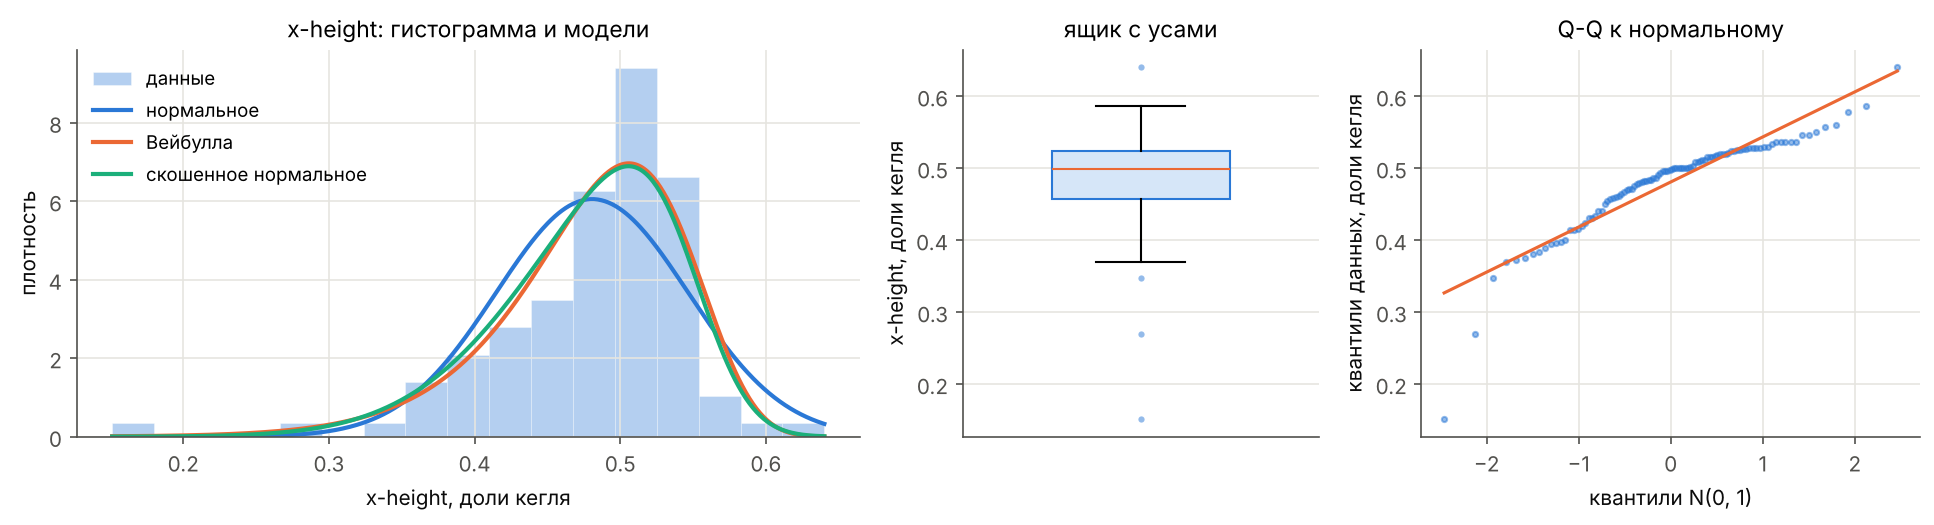

In [7]:
best_x_height = {nm: dist.fit(nm, x_x_height) for nm in ["norm"] + [d for d in fit_x_height.index if d != "norm"][:2]}
plots.eda_panel(x_x_height, "x-height", "доли кегля", best_x_height, "fonts_x_height_eda.png", bins="fd");

<a id="fig_x_height_eda"></a>
*Рис. 4. x-height: гистограмма с подобранными плотностями, ящик с усами, Q-Q к нормальному.*

**Результаты:**

- $N = 100$, среднее 0.481, медиана 0.499, СКО 0.0663, коэффициент вариации 13.8 %.
- Асимметрия $-1.66$, эксцесс $+5.58$; диапазон 0.151–0.640; выбросов по $1.5\cdot\mathrm{IQR}$: 4.
- Лучшее семейство по AIC: Вейбулла; D'Agostino $K^2$ для нормального: $p \approx 10^{-11}$.

**TODO КТвД: что видно на гистограмме и Q-Q, своими словами.**

<a id="rv2"></a>
## 3. Random Variable 02 (толщина штриха)

<sub>[↑ к содержанию](#toc)</sub>

<a id="rv2-desc"></a>
### 3.1 Description (природа события)

**Величина.** Толщина вертикали «l» в долях кегля; точность измерения $1/\mathrm{UPM}$ (у большинства шрифтов
$1/1000$ или $1/2048$ кегля), то есть $\le 0.001$.

**Событие.** Из коллекции случайно выбирается семейство шрифтов, у его Regular измеряется толщина вертикали «l».

**Что посчитано для проверки стохастической природы.** Прогноз величины по остальным измерениям
(высота прописных, контраст, ширина «o», средняя ширина букв, вес OS/2 и вторая величина) на 5-кратной кросс-валидации: линейная регрессия и $k = 5$ ближайших
соседей. Если бы величина вычислялась формулой из остальных, $R^2 \approx 1$, а остаток был бы порядка
точности $0.001$. Плюс разброс внутри одной категории: если бы категория (гротеск, антиква…) задавала величину,
внутри категории разброса бы не было.

**TODO КТвД: природа события своими словами.** _Вопросы: кто и почему выбирает толщину штриха шрифта? можно ли её
вычислить по другим пропорциям или по категории? что из расчёта ниже говорит «за» и «против»?_


<sub>[↑ к содержанию](#toc)</sub>

Линейная модель: R² = 0.539, СКО остатка 0.0332 кегля
5 ближайших соседей: R² = 0.156, СКО остатка 0.0446 кегля
Наблюдений в модели: 98 (без шрифтов с неизмеренным контрастом)
СКО самой величины 0.0490; точность измерения ≤ 0.001


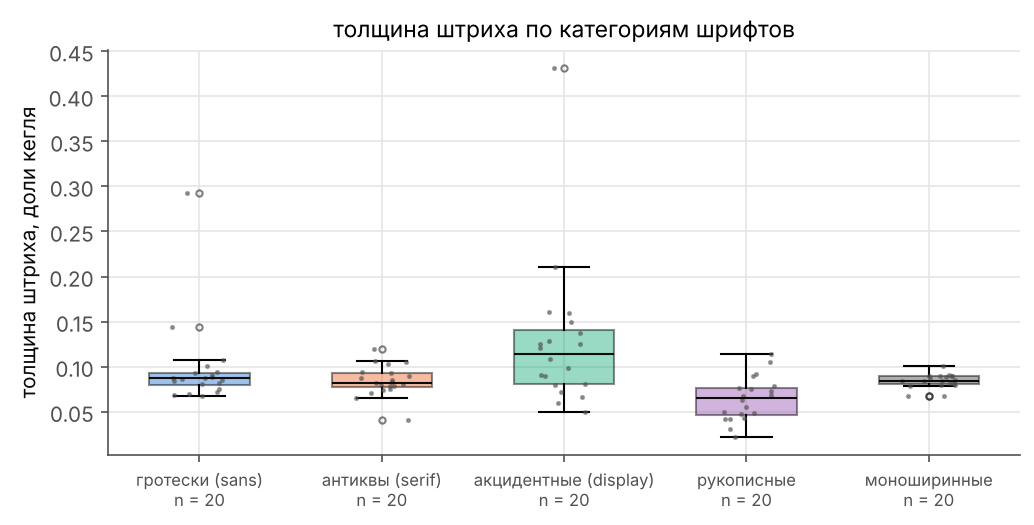

In [8]:
full = fonts.dropna(subset=OTHERS + ["x_height", "stem"])   # без шрифтов с неизмеренным контрастом
y = full["stem"].to_numpy()
Xo = full[[c for c in OTHERS + ["x_height", "stem"] if c != "stem"]].to_numpy()
lin = stochastic.cv_r2_linear(Xo, y, k=5, seed=SEED)
knn = stochastic.cv_r2_knn(Xo, y, k_neighbors=5, k=5, seed=SEED)
print(f"Линейная модель: R² = {lin['r2_cv']:.3f}, СКО остатка {lin['resid_std']:.4f} кегля")
print(f"5 ближайших соседей: R² = {knn['r2_cv']:.3f}, СКО остатка {knn['resid_std']:.4f} кегля")
print(f"Наблюдений в модели: {len(full)} (без шрифтов с неизмеренным контрастом)")
print(f"СКО самой величины {y.std(ddof=1):.4f}; точность измерения ≤ 0.001")
fp.box_by_category(fonts, "stem", "толщина штриха", "доли кегля", "fonts_stem_by_cat.png");

<a id="fig_stem_cat"></a>
*Рис. 5. Толщина штриха по категориям шрифтов: ящики с усами и сами наблюдения.*

**Результаты:**

- Линейная модель по остальным измерениям: $R^2 = 0.539$, СКО остатка 0.0332 кегля.
- 5 ближайших соседей: $R^2 = 0.156$, СКО остатка 0.0446 кегля.
- СКО самой величины 0.0490 (шрифтов в модели: 98), точность измерения $\le 0.001$: даже лучший остаток (0.0332) больше точности, отношение $\approx 33$.
- Средний по категориям разброс внутри категории составляет 74 % общего СКО.

<a id="rv2-eda"></a>
### 3.2 EDA & Distribution

<sub>[↑ к содержанию](#toc)</sub>

In [9]:
x_stem = fonts["stem"].to_numpy()
print("Выбросов по правилу 1.5·IQR:", dsc.iqr_outliers(x_stem).sum())
display(dsc.compare_table({"все": x_stem} | {c: g["stem"] for c, g in fonts.groupby("category")}).T)
fit_stem = dist.fit_candidates(x_stem)
fit_stem

Выбросов по правилу 1.5·IQR: 16


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
все,100.0,0.0915,2.3716e-03,0.0487,0.5320,0.0223,0.0727,0.0840,0.0931,0.4313,0.0204,0.0900,4.2790,24.7997,83.0,1.5625e-05
display,20.0,0.1272,6.7349e-03,0.0821,0.6454,0.0492,0.0809,0.1144,0.1408,0.4313,0.0599,0.1250,2.6643,7.6231,19.0,3.8415e-04
handwriting,20.0,0.0641,5.9992e-04,0.0245,0.3818,0.0223,0.0463,0.0653,0.0768,0.1145,0.0305,0.0223,0.3167,-0.6032,20.0,2.9893e-04
mono,20.0,0.0841,6.0857e-05,0.0078,0.0928,0.0670,0.0809,0.0840,0.0900,0.1010,0.0091,0.0900,-0.4659,0.8183,14.0,1.5625e-05
sans,20.0,0.0978,2.3984e-03,0.0490,0.5007,0.0670,0.0795,0.0869,0.0931,0.2931,0.0136,0.0879,3.4104,11.0725,19.0,1.0937e-04
serif,20.0,0.0845,2.8593e-04,0.0169,0.2001,0.0410,0.0773,0.0820,0.0931,0.1196,0.0158,0.0410,-0.2905,0.9405,20.0,4.8828e-04


,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
lognorm,3,200.2241,-394.4481,-386.6326,0.1572,"(0.3889, 0.0001, 0.084)"
skewnorm,3,185.8139,-365.6278,-357.8123,0.2471,"(4.3596, 0.0474, 0.0655)"
gamma,3,166.8052,-327.6103,-319.7948,0.3404,"(0.978, 0.0223, 0.0694)"
norm,2,160.8181,-317.6363,-312.4259,0.2497,"(0.0915, 0.0485)"
weibull_min,3,-inf,inf,inf,0.2986,"(0.7583, 0.06, 0.0195)"


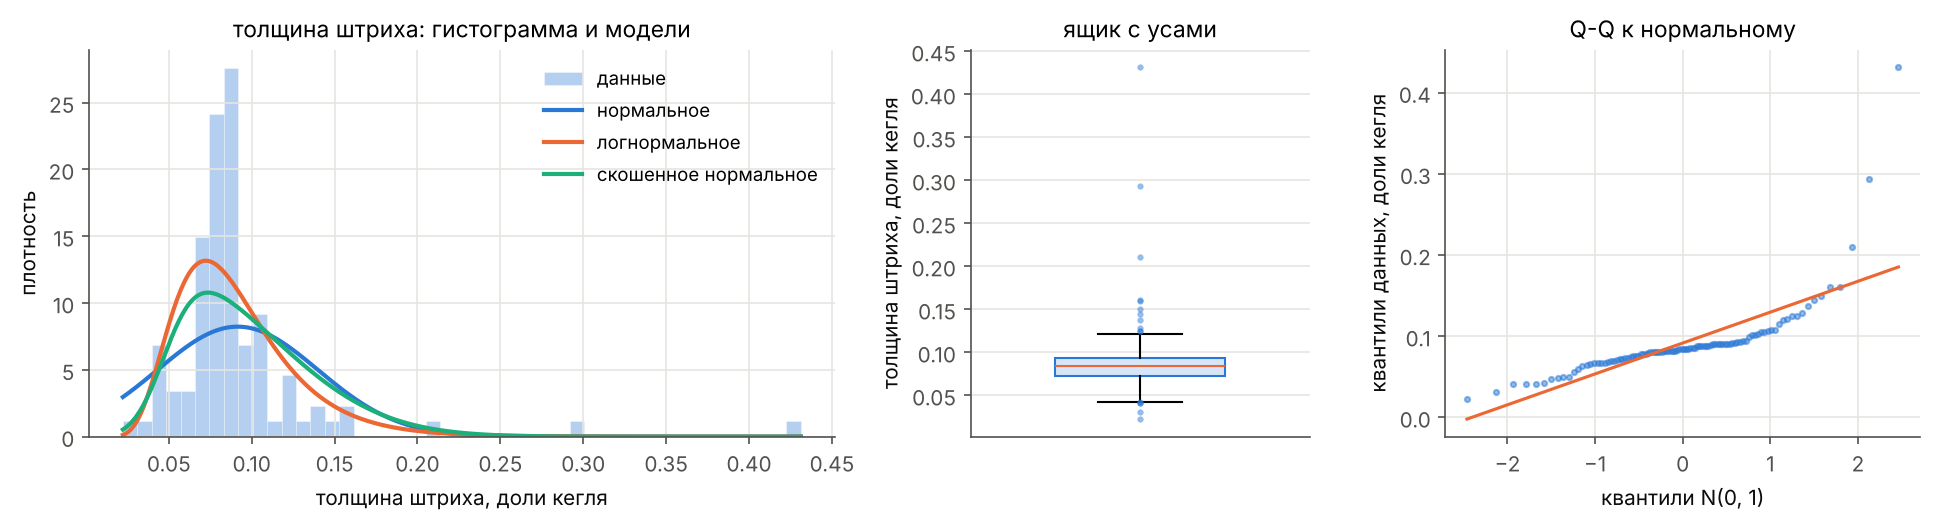

In [10]:
best_stem = {nm: dist.fit(nm, x_stem) for nm in ["norm"] + [d for d in fit_stem.index if d != "norm"][:2]}
plots.eda_panel(x_stem, "толщина штриха", "доли кегля", best_stem, "fonts_stem_eda.png", bins="fd");

<a id="fig_stem_eda"></a>
*Рис. 6. Толщина штриха: гистограмма с подобранными плотностями, ящик с усами, Q-Q к нормальному.*

**Результаты:**

- $N = 100$, среднее 0.092, медиана 0.084, СКО 0.0487, коэффициент вариации 53.2 %.
- Асимметрия $+4.28$, эксцесс $+24.80$; диапазон 0.022–0.431; выбросов по $1.5\cdot\mathrm{IQR}$: 16.
- Лучшее семейство по AIC: логнормальное; D'Agostino $K^2$ для нормального: $p \approx 10^{-28}$.

**TODO КТвД: что видно на гистограмме и Q-Q, своими словами.**

<a id="dep"></a>
## 4. Independence: x-height и толщина штриха

Обе величины одной природы: пропорции одной и той же буквы, их задаёт один дизайнер. По условию для таких величин
проверяется независимость. $H_0$: x-height и толщина штриха независимы. Проверки: корреляции Пирсона, Спирмена,
Кендалла; $\chi^2$ на таблице сопряжённости по квантилям; перестановочный тест для $\rho$ Спирмена
(2000 перестановок). Отдельно $\rho$ внутри каждой категории: общая связь может возникать только из-за смеси
категорий (парадокс Симпсона).


<sub>[↑ к содержанию](#toc)</sub>

,coef,p
method,,
pearson,0.3137,1.4807e-03
spearman,0.4006,3.6211e-05
kendall,0.2851,2.9867e-05


χ² = 23.7, df = 9, p = 0.00479, V Крамера = 0.281
перестановочный тест: ρ = 0.401, p = 0.0005
ρ внутри категорий: {'display': np.float64(0.01), 'handwriting': np.float64(0.698), 'mono': np.float64(0.655), 'sans': np.float64(0.452), 'serif': np.float64(0.556)}


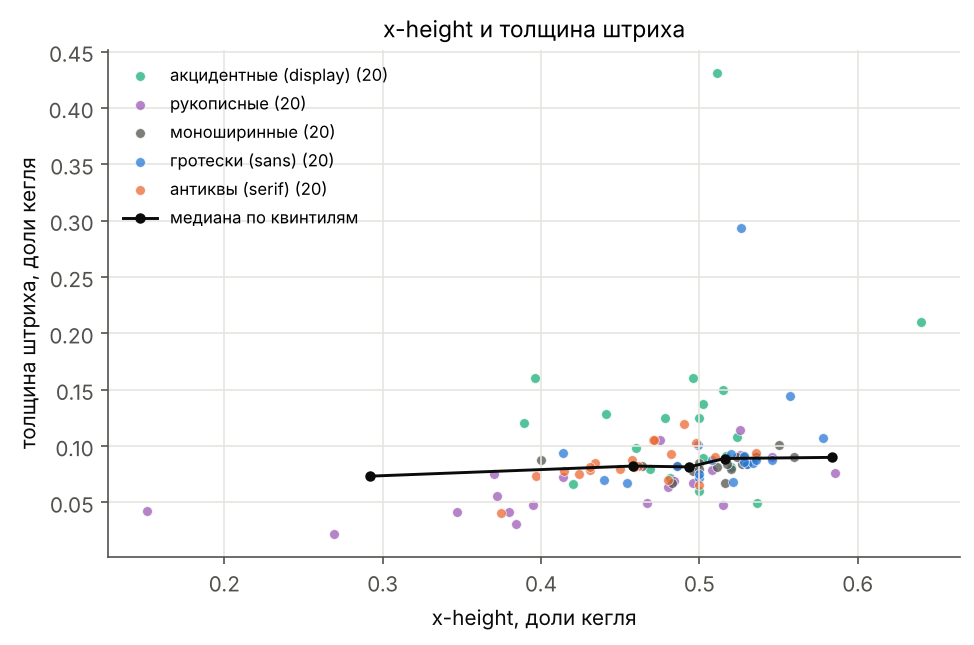

In [11]:
display(dependence.correlations(fonts.x_height, fonts.stem))
chi = dependence.chi2_independence(fonts.x_height, fonts.stem, bins=4 if len(fonts) >= 80 else 2)
perm = dependence.permutation_spearman(fonts.x_height, fonts.stem, n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.3g}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}")
print("ρ внутри категорий:", {c: round(stats.spearmanr(g.x_height, g.stem)[0], 3) for c, g in fonts.groupby("category") if len(g) >= 8})
fp.scatter_by_category(fonts, "x_height", "stem", "x-height, доли кегля", "толщина штриха, доли кегля",
                       "x-height и толщина штриха", "fonts_dependence.png");

<a id="fig7"></a>
*Рис. 7. x-height и толщина штриха; цвет — категория, чёрная линия — медиана толщины по квинтилям x-height.*

**Результаты:**

- Пирсон +0.314, Спирмен +0.401, Кендалл +0.285
  (для Спирмена $p \approx 10^{-5}$).
- $\chi^2 = 23.7$ при $\mathrm{df} = 9$, $p = 0.005$, $V$ Крамера 0.281.
- Перестановочный тест: $\rho = +0.401$, $p = 0.0005$. $H_0$ о независимости при $\alpha = 0.05$ **отвергается**.
- $\rho$ Спирмена внутри категорий: display +0.01, handwriting +0.70, mono +0.65, sans +0.45, serif +0.56.

**TODO КТвД: вывод о зависимости своими словами.** _Вопросы: есть ли связь, насколько она сильна? держится ли она
внутри категорий? как это объяснить с точки зрения дизайна шрифта?_

<a id="hyp"></a>
### 4.1 Гипотеза: у гротесков x-height больше, чем у антикв

В типографике принято считать, что у гротесков строчные выше, чем у антикв. Проверяем односторонним критерием
Манна–Уитни: $H_0$: $P(X_{\text{sans}} > X_{\text{serif}}) \le 1/2$, $\alpha = 0.05$.


<sub>[↑ к содержанию](#toc)</sub>

In [12]:
sans, serif = fonts.x_height[fonts.category == "sans"], fonts.x_height[fonts.category == "serif"]
h_sans = hyp.mann_whitney(sans, serif, alternative="greater")
print(f"медиана x-height: гротески {sans.median():.3f} (n = {len(sans)}), антиквы {serif.median():.3f} (n = {len(serif)})")
pd.Series(h_sans)

медиана x-height: гротески 0.521 (n = 20), антиквы 0.460 (n = 20)


test        Mann–Whitney (greater)
H0                  P(A > B) ≤ 1/2
stat                         330.5
p                           0.0002
decision              отвергаем H0
p_a_gt_b                    0.8263
dtype: object

**Результаты:** медиана x-height у гротесков 0.521, у антикв 0.460;
критерий Манна–Уитни $p = 0.0002$, $H_0$ **отвергается**.

<a id="resume"></a>
## 5. Resume

<a id="res-metrics"></a>
### 5.1 Итоговые метрики

<sub>[↑ к содержанию](#toc)</sub>

In [13]:
rows = []
for col, nm in [("x_height", "x-height"), ("stem", "толщина штриха")]:
    v = fonts[col]
    rows.append({"величина": nm, "N": len(v), "среднее": v.mean(), "СКО": v.std(), "медиана": v.median(),
                 "асимметрия": stats.skew(v), "эксцесс": stats.kurtosis(v),
                 "R² по остальным": stochastic.cv_r2_linear(full[[c for c in OTHERS + ["x_height", "stem"] if c != col]].to_numpy(), full[col].to_numpy(), k=5, seed=SEED)["r2_cv"],
                 "лучшая по AIC": dist.fit_candidates(v.to_numpy()).index[0]})
pd.DataFrame(rows).set_index("величина").round(4)

,N,среднее,СКО,медиана,асимметрия,эксцесс,R² по остальным,лучшая по AIC
величина,,,,,,,,
x-height,100,0.4807,0.0663,0.4985,-1.6591,5.5849,0.6711,weibull_min
толщина штриха,100,0.0915,0.0487,0.0840,4.2790,24.7997,0.5391,lognorm


<a id="res-concl"></a>
### 5.2 Выводы

**TODO КТвД: выводы своими словами** (преподаватель просит «как на лабах по физике»).
_Вопросы: почему x-height и толщина штриха — случайные величины? какие у них распределения? зависимы ли они и
почему? что подтвердила гипотеза про гротески? какие ограничения у коллекции (не случайный отбор, мало шрифтов
в категории, Google Fonts — не все шрифты мира)?_

<a id="res-lit"></a>
### 5.3 Литература

1. Брингхерст Р. Основы стиля в типографике. М.: Д. Аронов, 2006 (Bringhurst R. The Elements of Typographic Style).
2. Королькова А. Живая типографика. М.: IndexMarket, 2007.
3. Microsoft. OpenType specification: таблицы `head` (unitsPerEm), `OS/2` (sxHeight, usWeightClass), `hmtx`, `fvar`.
4. fontTools: библиотека для работы со шрифтами на Python. github.com/fonttools/fonttools.
5. Google Fonts: каталог шрифтов с открытой лицензией (SIL OFL). fonts.google.com.

**TODO КТвД:** добавить источники из библиотек (РГБ, РНБ, ИТМО, eLibrary): за подбор литературы отдельный балл.

<a id="res-marks"></a>
### 5.4 cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| КТвД: доп. датасет | [1](#ds) | | собственный датасет, собран и измерен своим скриптом |
| КТвД: случайная величина | [2.1](#rv1-desc), [3.1](#rv2-desc) | | $R^2$ по остальным измерениям и остаток против точности |
| КТвД: (не)зависимость | [4](#dep) | | корреляции, $\chi^2$, перестановочный тест, проверка внутри категорий |
| КТвД: EDA | [1.2](#ds-eda), [2.2](#rv1-eda), [3.2](#rv2-eda) | | описательные статистики, категории, подбор семейств |
| КТвД: гипотеза | [4.1](#hyp) | | гротески против антикв, Манн–Уитни |
| КТвД: оформление | [содержание](#toc) | | нумерация, якоря, скрытый код, подписи рисунков, LaTeX |


<sub>[↑ к содержанию](#toc)</sub>